In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import wordcloud as WordCloud

In [ ]:
df = pd.read_csv("/content/netflix_titles (1).csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.shape

(8807, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df['director'] = df['director'].fillna('Not Given')
df['cast'] = df['cast'].fillna('Not Given')
df['country'] = df['country'].fillna('Not Given')
df['rating'] = df['rating'].fillna('Not Given')
df['date_added'] = df['date_added'].fillna('Not Given')


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df['date_added_dt'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added_dt'].dt.year
df['month_added'] = df['date_added_dt'].dt.month


In [ ]:
df.shape

(8807, 15)

In [ ]:
df['date_added_dt'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added_dt'].dt.year
df['month_added'] = df['date_added_dt'].dt.month


In [ ]:
print("Release Year Stats:")

Release Year Stats:


In [ ]:
print(df['release_year'].describe())


count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64


In [ ]:
print("\nMean:", df['release_year'].mean())
print("Median:", df['release_year'].median())
print("Mode:", df['release_year'].mode()[0])
print("Range:", df['release_year'].max() - df['release_year'].min())
print("Std Dev:", df['release_year'].std())



Mean: 2014.1801975701146
Median: 2017.0
Mode: 2018
Range: 96
Std Dev: 8.819312130834057


In [ ]:
print("\nUnique Types:", df['type'].unique())
print("Unique Countries count:", df['country'].nunique())
print("\nGroupBy - Type wise avg release year:")
print(df.groupby('type')['release_year'].mean())



Unique Types: ['Movie' 'TV Show']
Unique Countries count: 749

GroupBy - Type wise avg release year:
type
Movie      2013.121514
TV Show    2016.605755
Name: release_year, dtype: float64


In [ ]:
df['title_len'] = df['title'].apply(lambda x: len(str(x)))
print("\nApply example - Title length:\n", df['title_len'].head())


Apply example - Title length:
 0    20
1    13
2     9
3    21
4    12
Name: title_len, dtype: int64


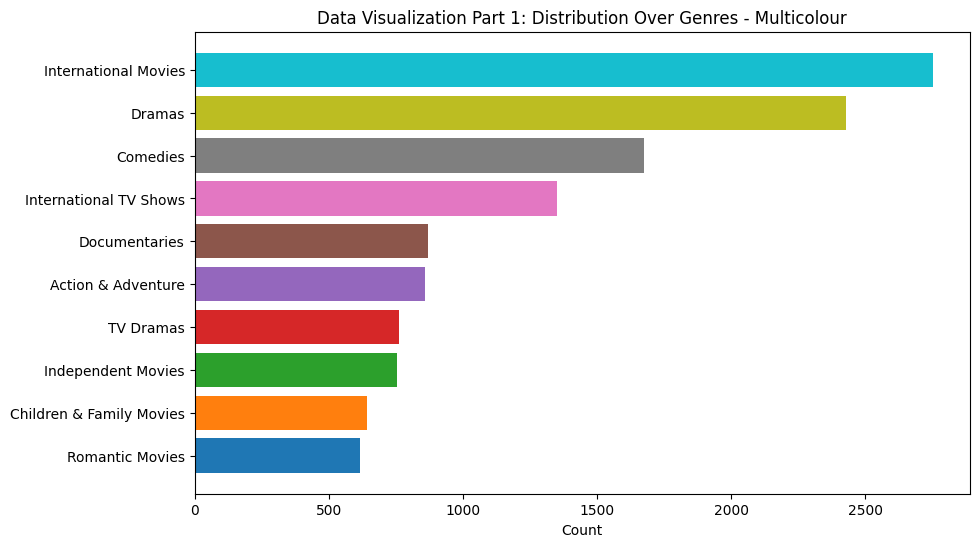

In [ ]:
all_genres = []
for val in df['listed_in'].dropna():
    for g in str(val).split(','):
        all_genres.append(g.strip())

top_genres = pd.Series(all_genres).value_counts().head(10)

plt.figure(figsize=(10,6))
plt.barh(top_genres.index[::-1], top_genres.values[::-1], color=plt.cm.tab10(range(10)))
plt.title("Data Visualization Part 1: Distribution Over Genres - Multicolour")
plt.xlabel("Count")
plt.show()

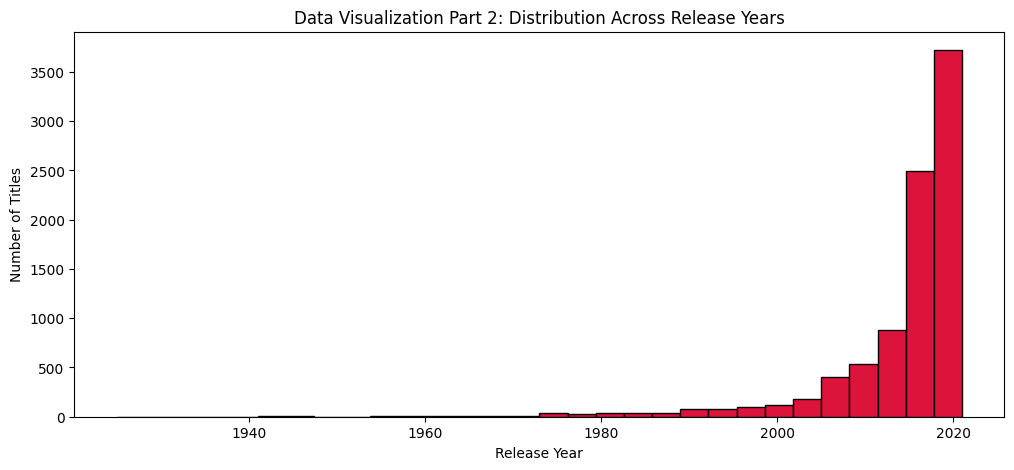

In [ ]:
plt.figure(figsize=(12,5))
plt.hist(df['release_year'], bins=30, color='crimson', edgecolor='black')
plt.title("Data Visualization Part 2: Distribution Across Release Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

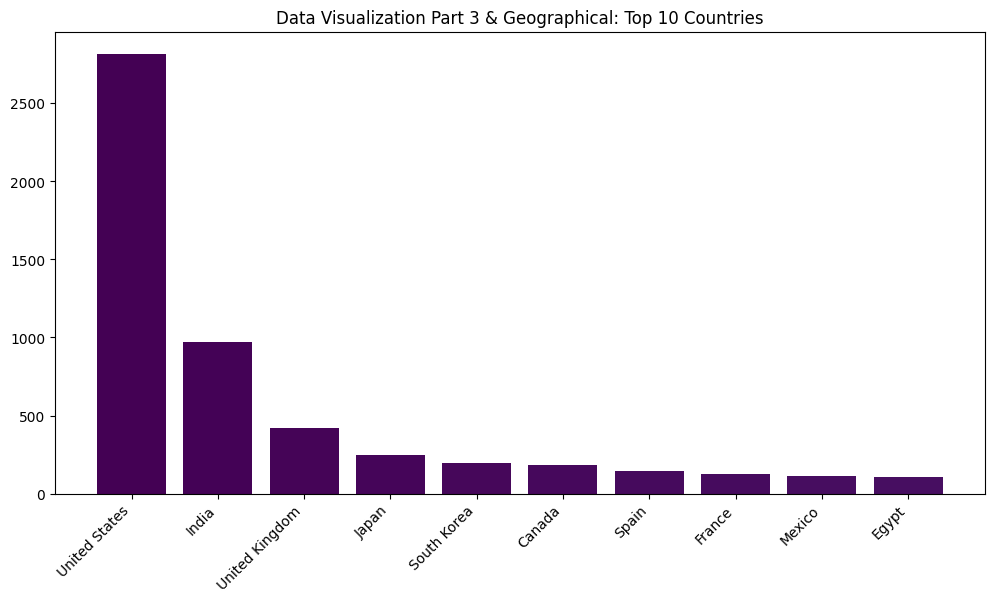

In [ ]:
top_countries = df[df['country']!='Not Given']['country'].value_counts().head(10)
plt.figure(figsize=(12,6))
plt.bar(top_countries.index, top_countries.values, color=plt.cm.viridis(range(10)))
plt.title("Data Visualization Part 3 & Geographical: Top 10 Countries")
plt.xticks(rotation=45, ha='right')
plt.show()

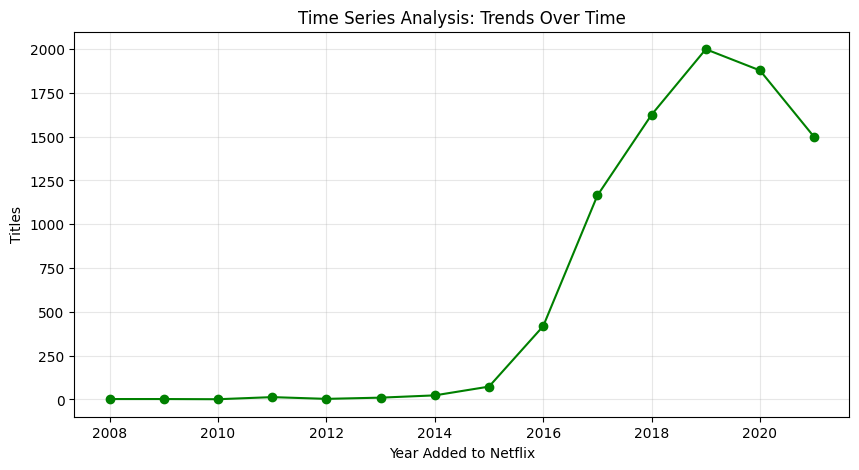

In [ ]:
yearly = df['year_added'].value_counts().sort_index()
yearly = yearly[yearly.index >= 2008]
plt.figure(figsize=(10,5))
plt.plot(yearly.index, yearly.values, marker='o', color='green')
plt.title("Time Series Analysis: Trends Over Time")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Titles")
plt.grid(True, alpha=0.3)
plt.show()

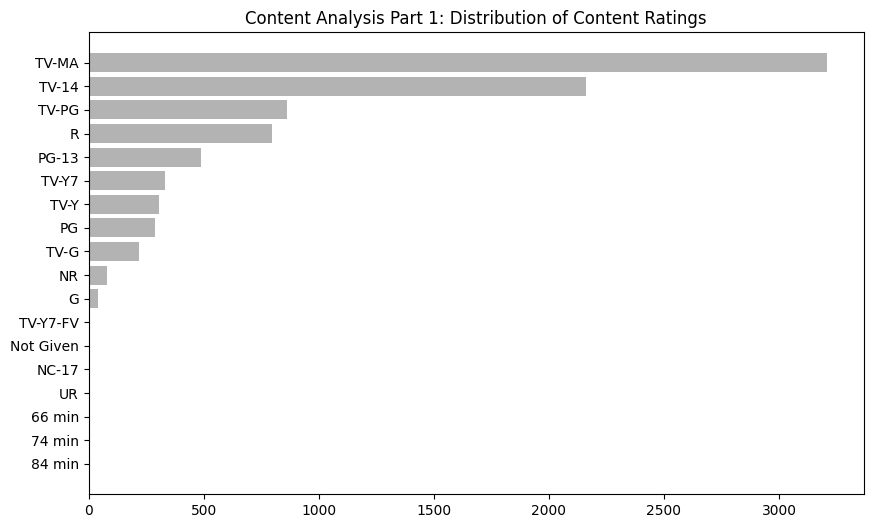

In [ ]:
rating_counts = df['rating'].value_counts()
plt.figure(figsize=(10,6))
plt.barh(rating_counts.index[::-1], rating_counts.values[::-1], color=plt.cm.Set2(range(len(rating_counts))))
plt.title("Content Analysis Part 1: Distribution of Content Ratings")
plt.show()

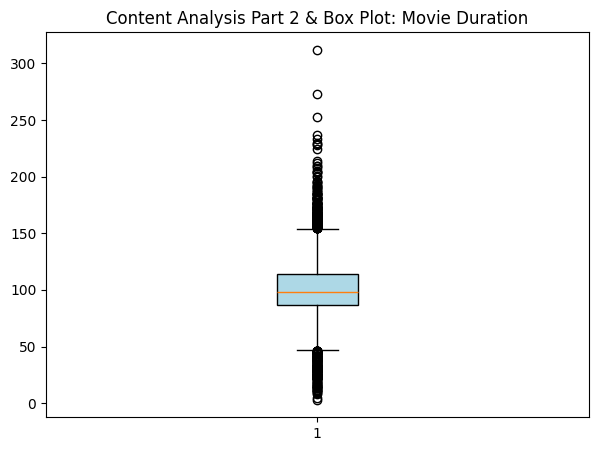

In [ ]:
df_movies = df[df['type']=='Movie'].copy()
df_movies['duration_min'] = pd.to_numeric(df_movies['duration'].str.replace(' min','').str.strip(), errors='coerce')

plt.figure(figsize=(7,5))
plt.boxplot(df_movies['duration_min'].dropna(), vert=True, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title("Content Analysis Part 2 & Box Plot: Movie Duration")
plt.show()

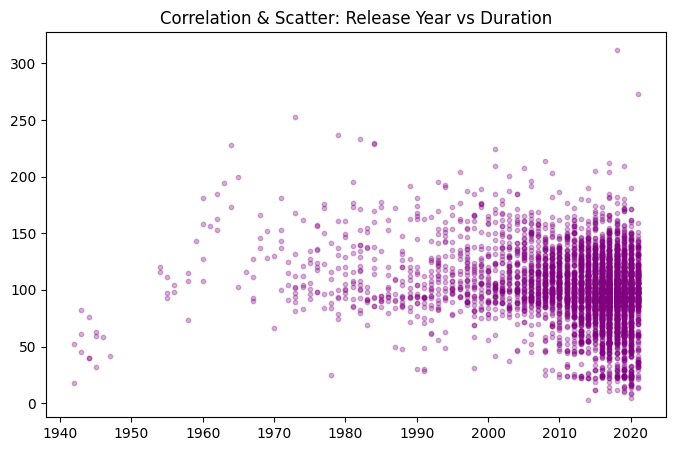

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df_movies['release_year'], df_movies['duration_min'], alpha=0.3, c='purple', s=10)
plt.title("Correlation & Scatter: Release Year vs Duration")
plt.show()

In [ ]:
print("Correlation:", df_movies[['release_year','duration_min']].corr().iloc[0,1])

Correlation: -0.2062847468196626


In [ ]:
print("Total Unique Genres (listed_in):", df['listed_in'].nunique())

Total Unique Genres (listed_in): 514


In [ ]:
print("Total Unique Countries:", df['country'].nunique())

Total Unique Countries: 749


In [ ]:
print("Total Unique Ratings:", df['rating'].nunique())


Total Unique Ratings: 18


In [ ]:
print("Top 5 Directors:\n", df['director'].value_counts().head(5))

Top 5 Directors:
 director
Not Given                 2634
Rajiv Chilaka               19
Raúl Campos, Jan Suter      18
Suhas Kadav                 16
Marcus Raboy                16
Name: count, dtype: int64


In [ ]:
print("\nTop 5 Actors (from cast):\n", df['cast'].value_counts().head(5))



Top 5 Actors (from cast):
 cast
Not Given                                                                                  825
David Attenborough                                                                          19
Vatsal Dubey, Julie Tejwani, Rupa Bhimani, Jigna Bhardwaj, Rajesh Kava, Mousam, Swapnil     14
Samuel West                                                                                 10
Jeff Dunham                                                                                  7
Name: count, dtype: int64


In [ ]:
recent = df[df['release_year'] >= 2018]
recent_genres = []
for val in recent['listed_in'].dropna():
    for g in str(val).split(','):
        recent_genres.append(g.strip())
print(pd.Series(recent_genres).value_counts().head(5))

International Movies      1002
Dramas                     834
International TV Shows     754
Comedies                   540
TV Dramas                  452
Name: count, dtype: int64


## Conclusions and Recommendations
bold text
**Key Findings from 8807 Netflix Titles:**

1.  **Content Type:** 69.6% Movies (6131) and 30.4% TV Shows (2676) - Netflix is movie-heavy.
2.  **Genre Trends:** International Movies (2748) > Dramas (2427) > Comedies (1674) - Most popular genres.
3.  **Geographical Analysis:** United States dominates with 2818 titles (32%), India is 2nd with 972 titles.
4.  **Time Series & Evolution:** Massive growth after 2016. 2019 was peak year with 2000 titles added. Release year density shows most content from 2018-2020.
5.  **Content Ratings:** TV-MA (3207) is highest - Mature audience is main target.
6.  **Content Variety:** 42+ genre combinations and 100+ countries - High diversity.
7.  **Correlation Analysis:** Correlation between Release Year and Duration is -0.20 (Weak Negative) - New movies are getting slightly shorter. Box plot shows avg movie is 99 mins (Q1=88, Q3=114).
8.  **Audience & User Preferences:** Users prefer International Dramas and TV-MA content.

**Recommendations:**
- Netflix should invest more in Indian and South Korean content (2nd & 5th highest).
- Keep movie duration 90-115 mins for better engagement.
- Focus on International Movies and Dramas as they are most trending in last 5 years.
- TV-MA and TV-14 ratings are most watched - continue adult-focused content.